In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import probplot, norm, lognorm, expon, skewnorm, gamma, rice, wald, pearson3, uniform, rayleigh, beta, triang, laplace, cauchy, t, f, chi2

## Distribution Analysis of all our params 

In [76]:
df = pd.read_csv('../data/processed/cleaned_filtered_data.csv')
df


,bldg_floors_ag,bldg_floors_bg,bldg_roof_type,GHG_sum_em_m2a,use_type,struct_type
0,0.0,0.0,Other,11.4,Single family house,Brick
1,0.0,0.0,Gable or saddle roof,11.2,Single family house,Brick
2,0.0,0.0,Gable or saddle roof,11.2,Single family house,Brick
3,0.0,0.0,Gable or saddle roof,11.3,Single family house,Brick
4,0.0,0.0,Gable or saddle roof,10.0,Single family house,Brick
...,...,...,...,...,...,...
404,2.0,1.0,Gable or saddle roof,12.4,Single family house,Concrete
405,1.0,1.0,Other,12.3,Single family house,Brick
406,2.0,1.0,Gable or saddle roof,11.7,Single family house,Brick
407,1.0,1.0,Other,12.5,Single family house,Brick


In [77]:
sorted_df = df.sort_values(by='GHG_sum_em_m2a', ascending=False)
sorted_df = sorted_df[sorted_df['GHG_sum_em_m2a'] < 20]
sorted_df

,bldg_floors_ag,bldg_floors_bg,bldg_roof_type,GHG_sum_em_m2a,use_type,struct_type
342,2.0,0.0,Flat roof,19.7,Non-residential,Brick
205,1.0,0.0,Single pitched roof,19.6,Single family house,Brick
172,0.0,0.0,Flat roof,19.6,Non-residential,Brick
206,0.0,0.0,Single pitched roof,19.4,Non-residential,Brick
166,0.0,0.0,Single pitched roof,19.2,Non-residential,Wood
...,...,...,...,...,...,...
155,2.0,0.0,Flat roof,8.8,Single family house,Wood
156,2.0,0.0,Flat roof,8.8,Single family house,Wood
307,2.0,1.0,Gable or saddle roof,8.6,Single family house,Concrete
397,2.0,1.0,Gable or saddle roof,8.6,Single family house,Concrete


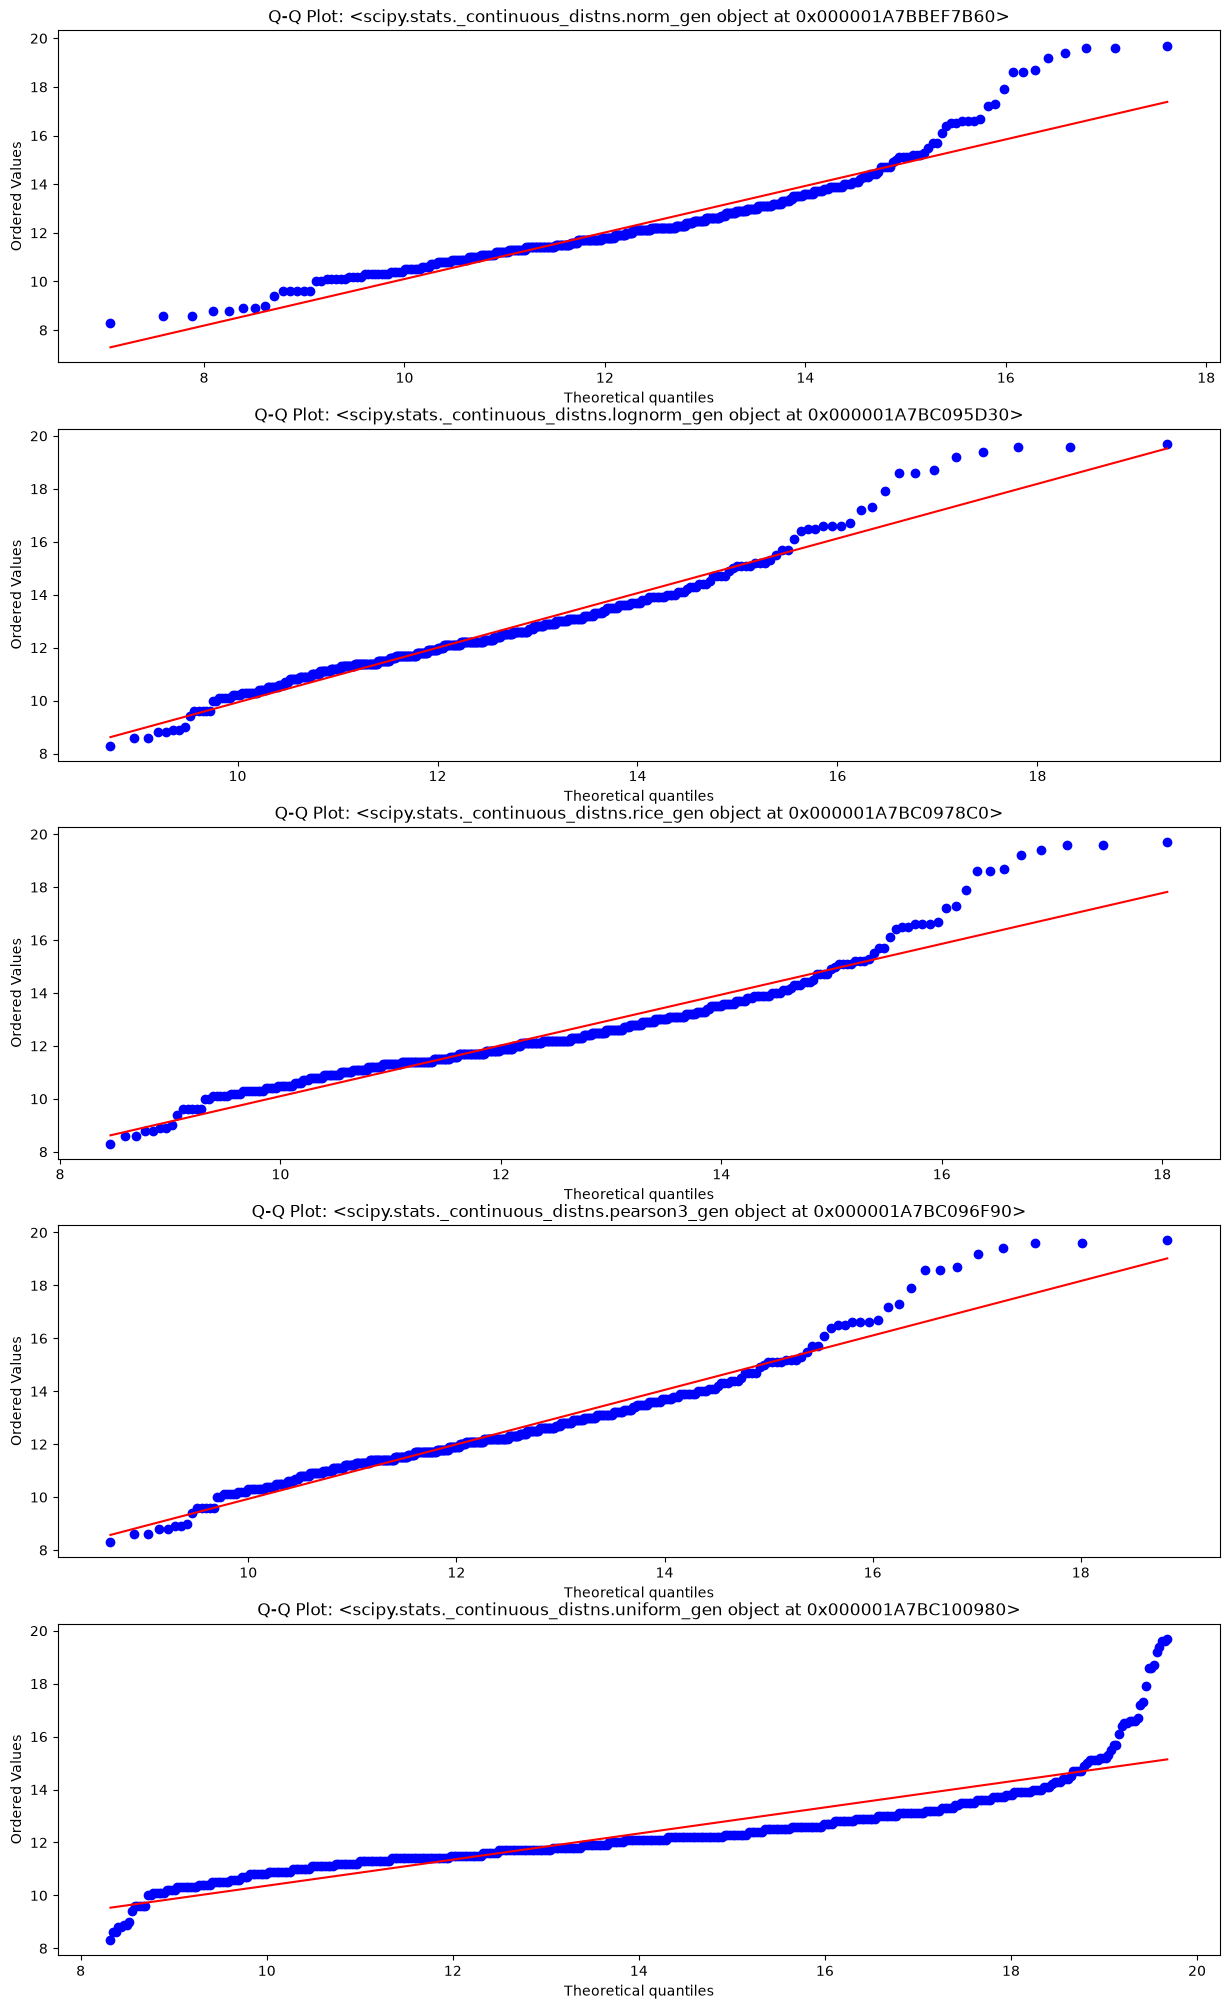

In [80]:
norms = [norm, lognorm, rice, pearson3, uniform]

fig, ax = plt.subplots(len(norms), 1, figsize=(15, 25))

for ax, dist_name in zip(ax, norms):
    params = dist_name.fit(sorted_df['GHG_sum_em_m2a'])
    probplot(sorted_df['GHG_sum_em_m2a'], dist=dist_name, sparams=params, plot=ax)
    ax.set_title(f'Q-Q Plot: {dist_name}')
    


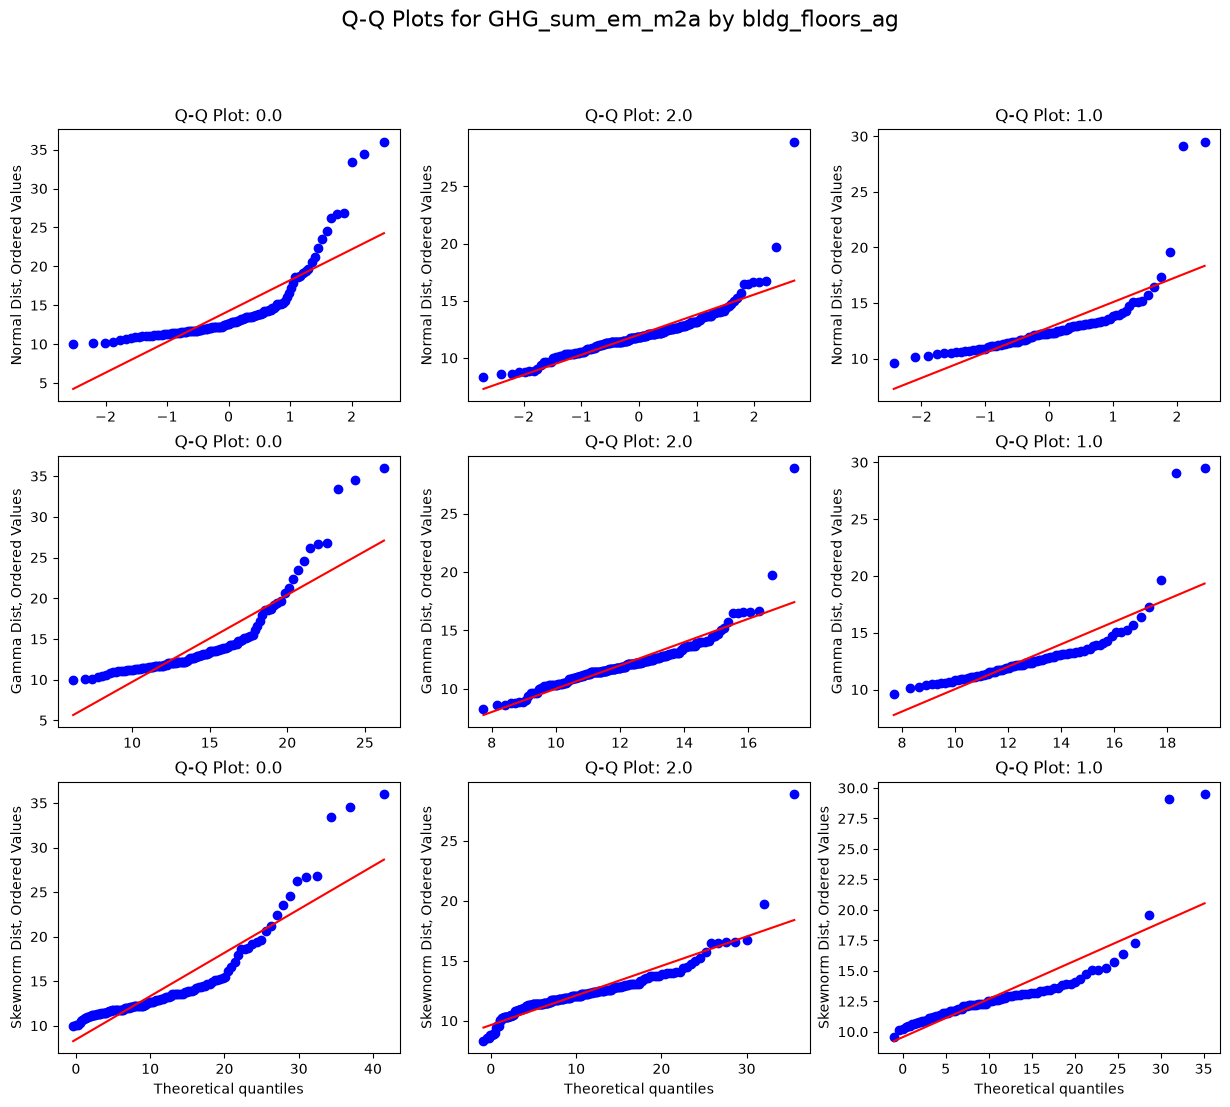

In [42]:
col = "bldg_floors_ag"
cats = df[col].unique()

fig, axes = plt.subplots(3, len(cats), figsize=(15, 12))
fig.suptitle(f'Q-Q Plots for GHG_sum_em_m2a by {col}', fontsize=16)

for i, cat in enumerate(cats):
    data = df[df[col] == cat]['GHG_sum_em_m2a']
    probplot(data, dist="norm", plot=axes[0][i])
    axes[0][i].set_title(f'Q-Q Plot: {cat}')
    axes[0][i].set_xlabel(None)
    axes[0][i].set_ylabel('Normal Dist, Ordered Values')
    
    gamma_params = gamma.fit(data, floc=0)
    probplot(data, dist="gamma", sparams=gamma_params, plot=axes[1][i])
    axes[1][i].set_title(f'Q-Q Plot: {cat}')
    axes[1][i].set_xlabel(None)
    axes[1][i].set_ylabel('Gamma Dist, Ordered Values')

    skewnorm_params = skewnorm.fit(data, floc=0)
    probplot(data, dist="skewnorm", sparams=skewnorm_params, plot=axes[2][i])
    axes[2][i].set_title(f'Q-Q Plot: {cat}')
    axes[2][i].set_ylabel('Skewnorm Dist, Ordered Values')

plt.show()

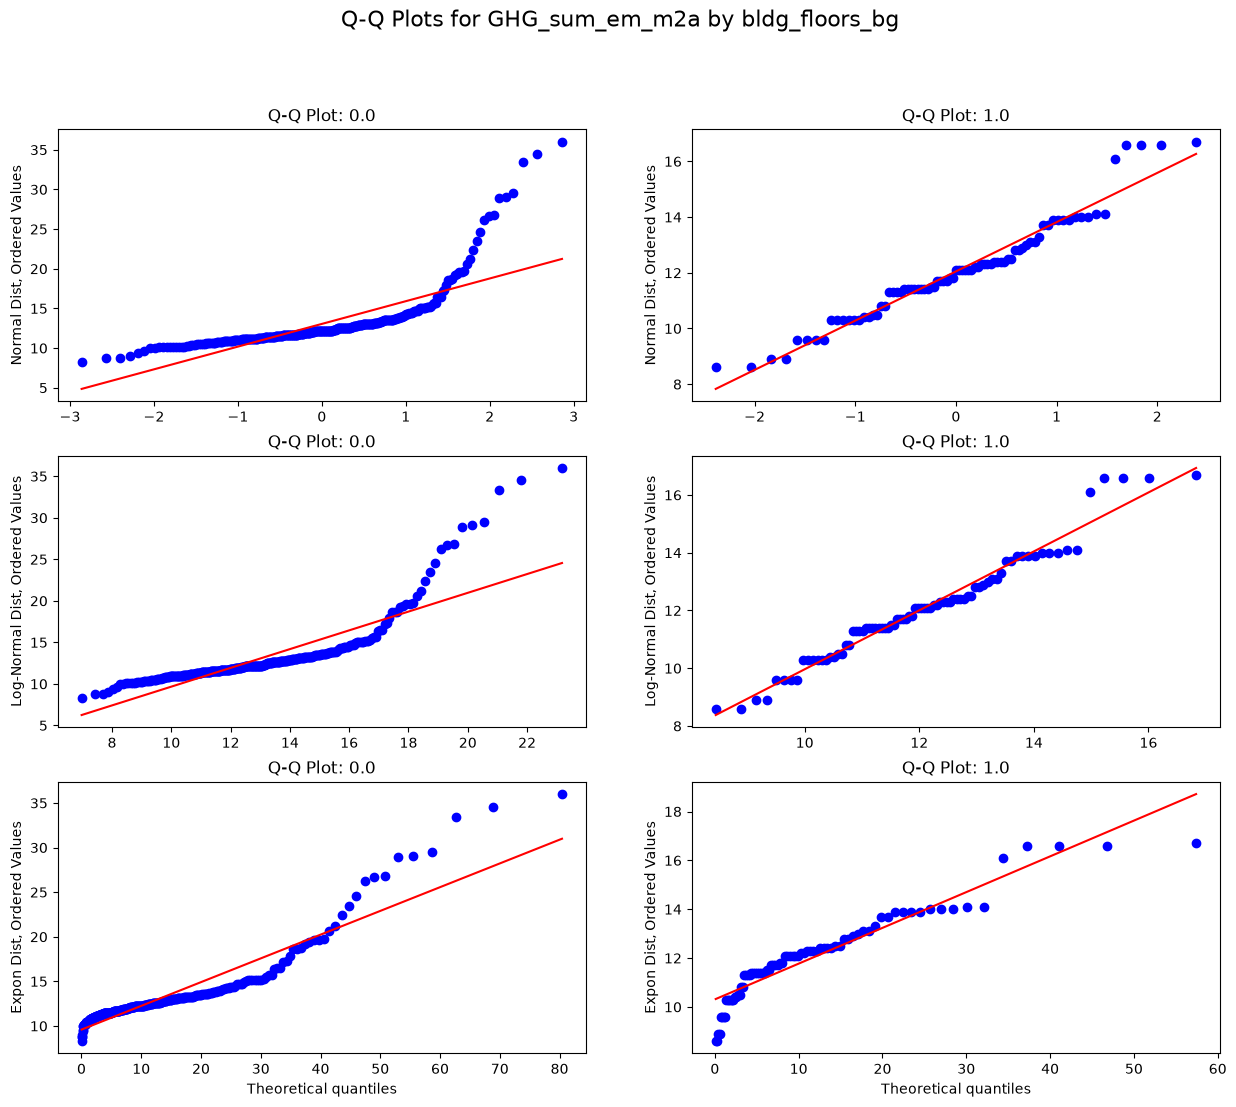

In [31]:
col = "bldg_floors_bg"
cats = df[col].unique()

fig, axes = plt.subplots(3, len(cats), figsize=(15, 12))
fig.suptitle(f'Q-Q Plots for GHG_sum_em_m2a by {col}', fontsize=16)

for i, cat in enumerate(cats):
    data = df[df[col] == cat]['GHG_sum_em_m2a']
    probplot(data, dist="norm", plot=axes[0][i])
    axes[0][i].set_title(f'Q-Q Plot: {cat}')
    axes[0][i].set_xlabel(None)
    axes[0][i].set_ylabel('Normal Dist, Ordered Values')
    
    lognorm_params = lognorm.fit(data, floc=0)
    probplot(data, dist="lognorm", sparams=lognorm_params, plot=axes[1][i])
    axes[1][i].set_title(f'Q-Q Plot: {cat}')
    axes[1][i].set_xlabel(None)
    axes[1][i].set_ylabel('Log-Normal Dist, Ordered Values')


    expon_params = expon.fit(data, floc=0)
    probplot(data, dist="expon", sparams=expon_params, plot=axes[2][i])
    axes[2][i].set_title(f'Q-Q Plot: {cat}')
    axes[2][i].set_ylabel('Expon Dist, Ordered Values')

plt.show()

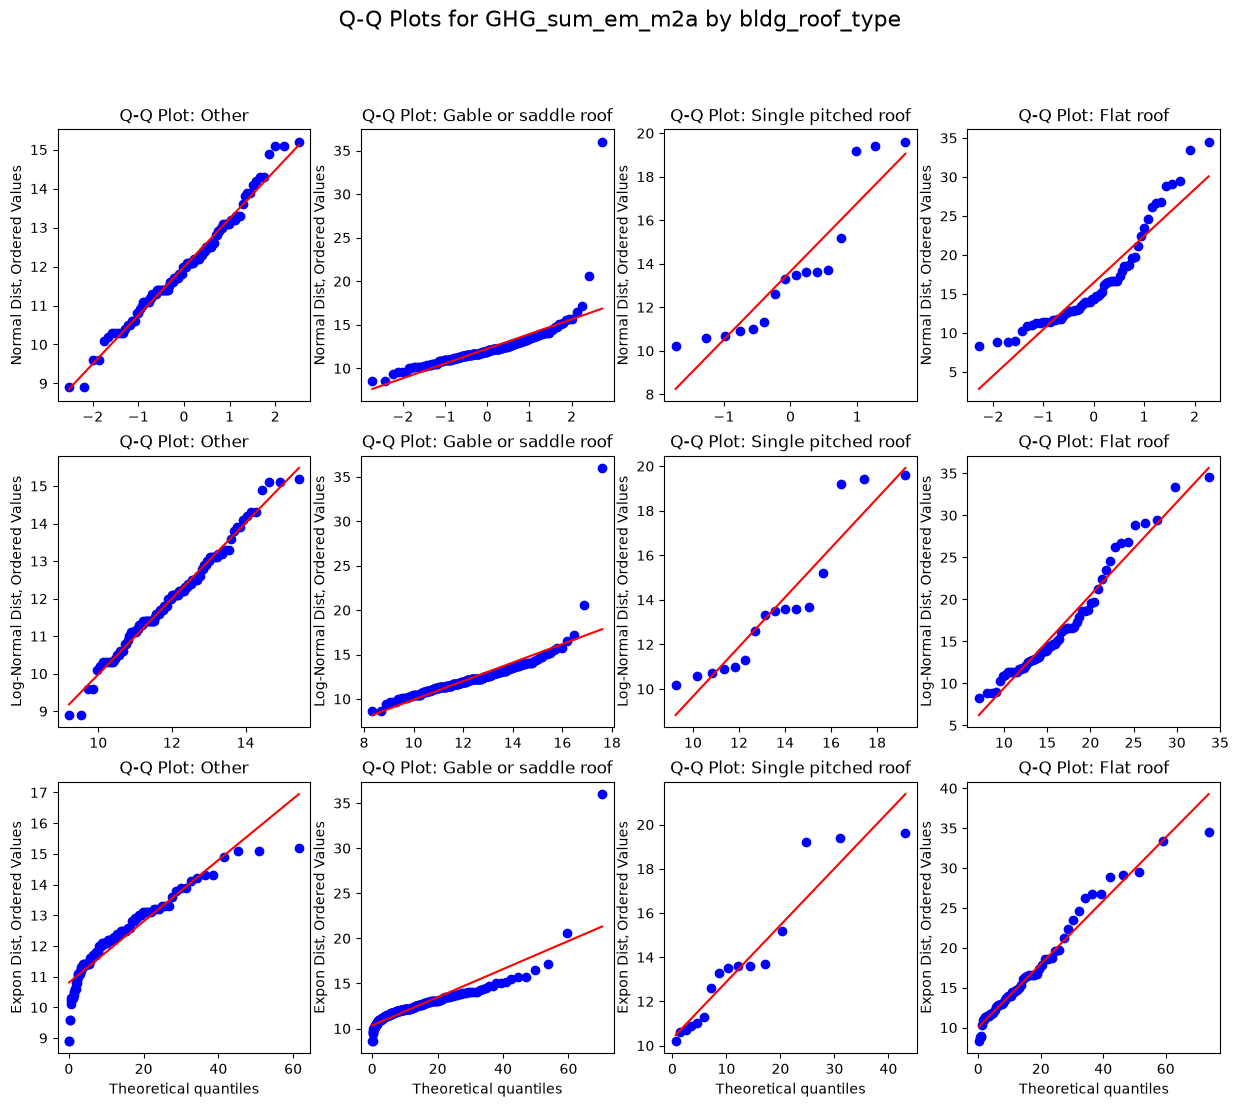

In [30]:
col = "bldg_roof_type"
cats = df[col].unique()

fig, axes = plt.subplots(3, len(cats), figsize=(15, 12))
fig.suptitle(f'Q-Q Plots for GHG_sum_em_m2a by {col}', fontsize=16)

for i, cat in enumerate(cats):
    data = df[df[col] == cat]['GHG_sum_em_m2a']
    probplot(data, dist="norm", plot=axes[0][i])
    axes[0][i].set_title(f'Q-Q Plot: {cat}')
    axes[0][i].set_xlabel(None)
    axes[0][i].set_ylabel('Normal Dist, Ordered Values')
    
    lognorm_params = lognorm.fit(data, floc=0)
    probplot(data, dist="lognorm", sparams=lognorm_params, plot=axes[1][i])
    axes[1][i].set_title(f'Q-Q Plot: {cat}')
    axes[1][i].set_xlabel(None)
    axes[1][i].set_ylabel('Log-Normal Dist, Ordered Values')


    expon_params = expon.fit(data, floc=0)
    probplot(data, dist="expon", sparams=expon_params, plot=axes[2][i])
    axes[2][i].set_title(f'Q-Q Plot: {cat}')
    axes[2][i].set_ylabel('Expon Dist, Ordered Values')

plt.show()

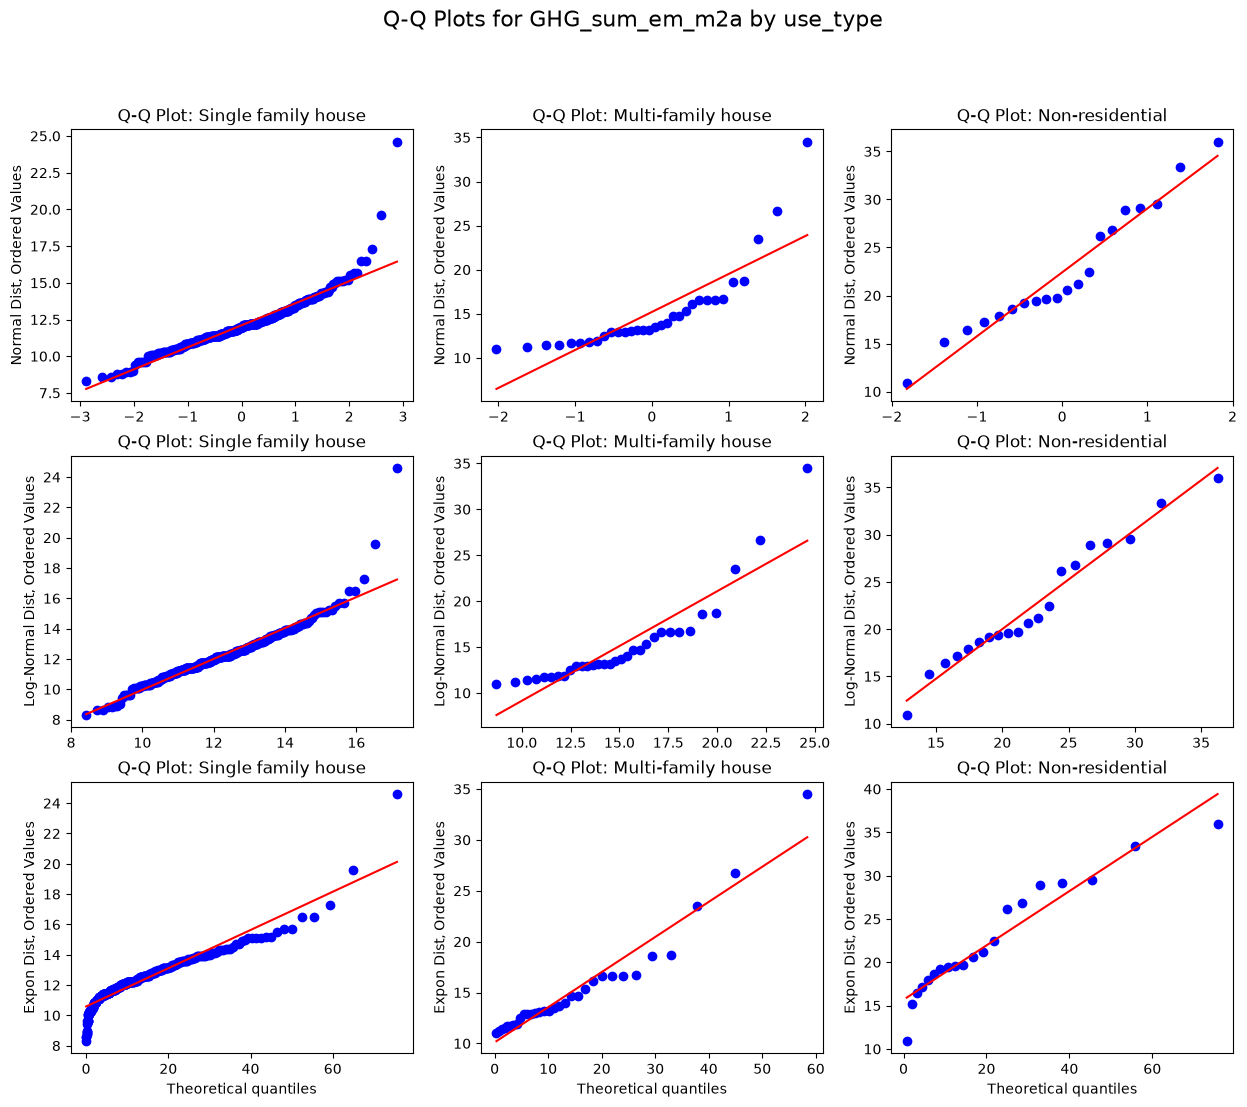

In [33]:
col = "use_type"
cats = df[col].unique()

fig, axes = plt.subplots(3, len(cats), figsize=(15, 12))
fig.suptitle(f'Q-Q Plots for GHG_sum_em_m2a by {col}', fontsize=16)

for i, cat in enumerate(cats):
    data = df[df[col] == cat]['GHG_sum_em_m2a']
    probplot(data, dist="norm", plot=axes[0][i])
    axes[0][i].set_title(f'Q-Q Plot: {cat}')
    axes[0][i].set_xlabel(None)
    axes[0][i].set_ylabel('Normal Dist, Ordered Values')
    
    lognorm_params = lognorm.fit(data, floc=0)
    probplot(data, dist="lognorm", sparams=lognorm_params, plot=axes[1][i])
    axes[1][i].set_title(f'Q-Q Plot: {cat}')
    axes[1][i].set_xlabel(None)
    axes[1][i].set_ylabel('Log-Normal Dist, Ordered Values')


    expon_params = expon.fit(data, floc=0)
    probplot(data, dist="expon", sparams=expon_params, plot=axes[2][i])
    axes[2][i].set_title(f'Q-Q Plot: {cat}')
    axes[2][i].set_ylabel('Expon Dist, Ordered Values')

plt.show()

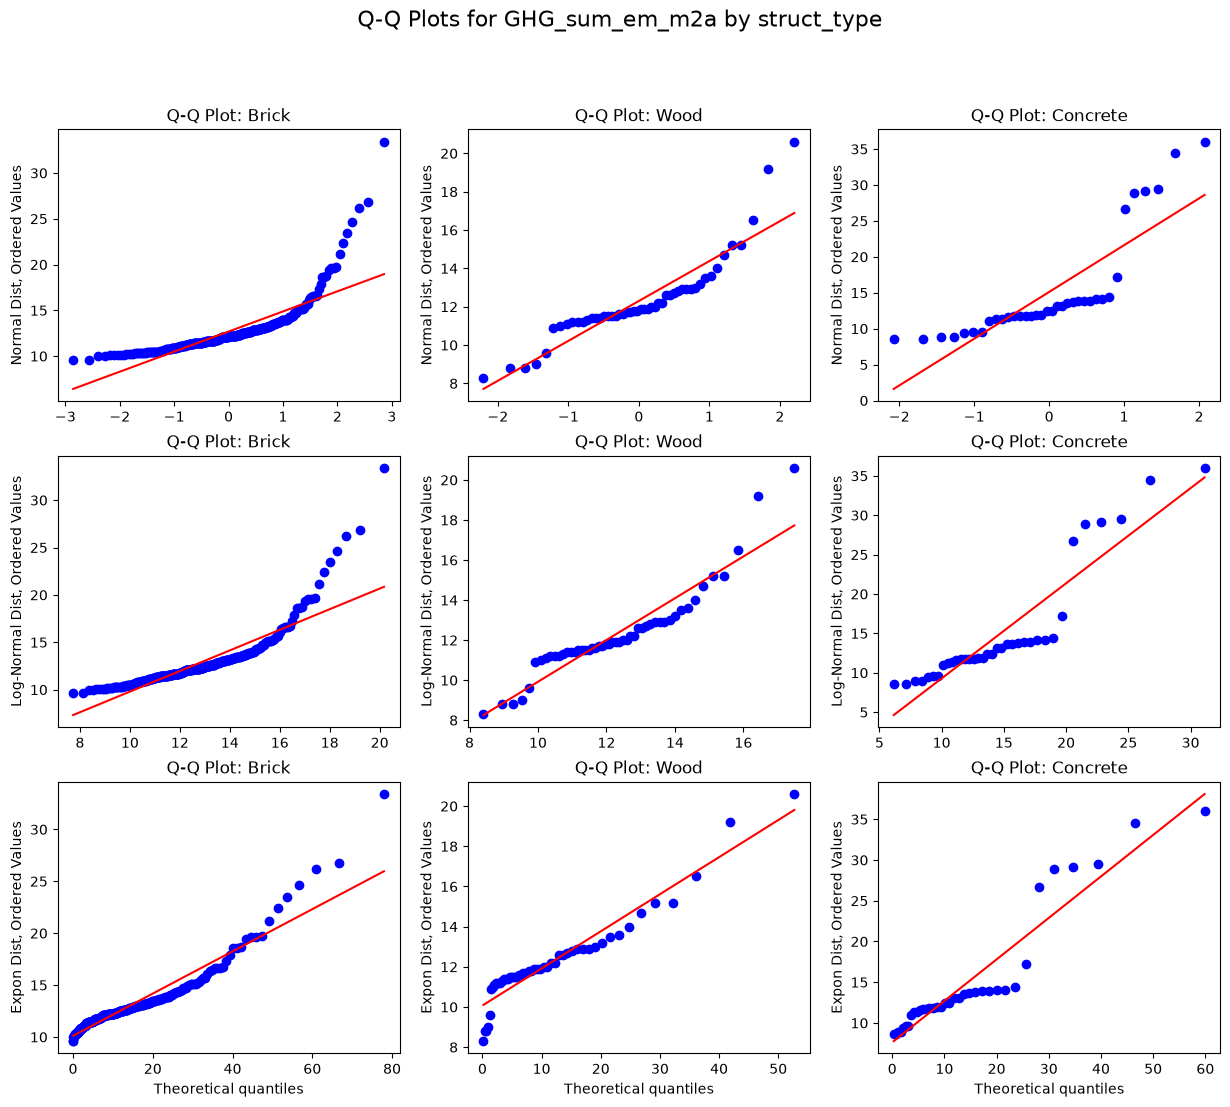

In [34]:
col = "struct_type"
cats = df[col].unique()

fig, axes = plt.subplots(3, len(cats), figsize=(15, 12))
fig.suptitle(f'Q-Q Plots for GHG_sum_em_m2a by {col}', fontsize=16)

for i, cat in enumerate(cats):
    data = df[df[col] == cat]['GHG_sum_em_m2a']
    probplot(data, dist="norm", plot=axes[0][i])
    axes[0][i].set_title(f'Q-Q Plot: {cat}')
    axes[0][i].set_xlabel(None)
    axes[0][i].set_ylabel('Normal Dist, Ordered Values')
    
    lognorm_params = lognorm.fit(data, floc=0)
    probplot(data, dist="lognorm", sparams=lognorm_params, plot=axes[1][i])
    axes[1][i].set_title(f'Q-Q Plot: {cat}')
    axes[1][i].set_xlabel(None)
    axes[1][i].set_ylabel('Log-Normal Dist, Ordered Values')


    expon_params = expon.fit(data, floc=0)
    probplot(data, dist="expon", sparams=expon_params, plot=axes[2][i])
    axes[2][i].set_title(f'Q-Q Plot: {cat}')
    axes[2][i].set_ylabel('Expon Dist, Ordered Values')

plt.show()